# Notebook 1 · Cinemática inversa del ABB IRB 120 por el método de Pieper

**IMT-342 Robótica · Hito 2.** Dada la pose deseada del efector, calcular los seis ángulos articulares **de forma analítica**
(sin MoveIt ni resolvedores numéricos).

**Idea.** Los ejes 4, 5 y 6 se cortan en un punto, el *centro de muñeca* $p_{wc}=p_{tool0}-d_6\,z_6$, que solo depende de $q_1,q_2,q_3$.

1. **Posición** ($q_1,q_2,q_3$): $q_1=\operatorname{atan2}(y,x)$ (o $+\pi$) y, en el plano del brazo, ley de cosenos con $L_2=0.270$, $L_3=\sqrt{d_4^2+a_3^2}$.
2. **Orientación** ($q_4,q_5,q_6$): $R_3^6=R_0^{3\,T}R=R_z(q_4)R_y(-q_5)R_z(q_6+\pi)$, un Euler ZYZ.
3. Resultan **hasta 8 soluciones** (2 brazo × 2 codo × 2 muñeca); se filtran por límites articulares y se comprueban con la cinemática directa.

In [1]:
import sys
from pathlib import Path
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="Unable to import Axes3D")
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().resolve().parent))   # carpeta hito2/ (paquete irb120)
np.set_printoptions(precision=4, suppress=True)

from irb120.dh import forward_kinematics, forward_kinematics_tcp, position_error_m, rotation_error_rad, DH_PARAMETERS
from irb120.pieper import inverse_kinematics, inverse_kinematics_tcp, LIMITS_RAD
from irb120.transforms import rpy_to_matrix, pose_matrix
from irb120.jacobian import joint_frames

print("Tabla DH (d, a, alpha, offset):")
for i, p in enumerate(DH_PARAMETERS, 1):
    print(f"  eje {i}: d={p.d_m:.3f}  a={p.a_m:.3f}  alpha={np.rad2deg(p.alpha_rad):7.1f} deg  offset={np.rad2deg(p.theta_offset_rad):6.1f} deg")

Tabla DH (d, a, alpha, offset):
  eje 1: d=0.290  a=0.000  alpha=  -90.0 deg  offset=   0.0 deg
  eje 2: d=0.000  a=0.270  alpha=    0.0 deg  offset= -90.0 deg
  eje 3: d=0.000  a=0.070  alpha=  -90.0 deg  offset=   0.0 deg
  eje 4: d=0.302  a=0.000  alpha=   90.0 deg  offset=   0.0 deg
  eje 5: d=0.000  a=0.000  alpha=  -90.0 deg  offset=   0.0 deg
  eje 6: d=0.072  a=0.000  alpha=    0.0 deg  offset= 180.0 deg


## 1. Ida y vuelta: FK → IK
Se parte de una postura conocida, se calcula la pose del TCP y se resuelve la IK tomando la postura original como referencia.

In [2]:
q = np.deg2rad([30, -20, 15, 40, -35, 60])
T = forward_kinematics_tcp(q)
print("Pose del TCP:\n", T)
solutions = inverse_kinematics_tcp(T, q)
print(f"\n{len(solutions)} soluciones validas:")
for s in solutions:
    reached = forward_kinematics_tcp(np.array(s.q))
    print(f"  {s.arm:6s}/{s.elbow:6s}/{s.wrist}  q [deg] = {np.rad2deg(s.q).round(2)}  error pos = {position_error_m(T, reached):.1e} m")
assert np.allclose(solutions[0].q, q, atol=1e-6)

Pose del TCP:
 [[-0.2343 -0.4573  0.8579  0.3228]
 [ 0.9348 -0.3483  0.0696  0.1132]
 [ 0.267   0.8182  0.5091  0.7273]
 [ 0.      0.      0.      1.    ]]

4 soluciones validas:
  frente/arriba/q5+  q [deg] = [ 30. -20.  15.  40. -35.  60.]  error pos = 2.5e-16 m
  atras /arriba/q5+  q [deg] = [-150.    -80.11   15.    -21.84  -82.27  -82.41]  error pos = 2.5e-16 m
  atras /arriba/q5-  q [deg] = [-150.    -80.11   15.    158.16   82.27   97.59]  error pos = 2.3e-16 m
  frente/arriba/q5-  q [deg] = [  30.  -20.   15. -140.   35. -120.]  error pos = 2.5e-16 m


## 2. Las configuraciones alcanzan la misma pose
Vista lateral (x–z) del brazo en cada solución: configuraciones distintas, mismo efector.

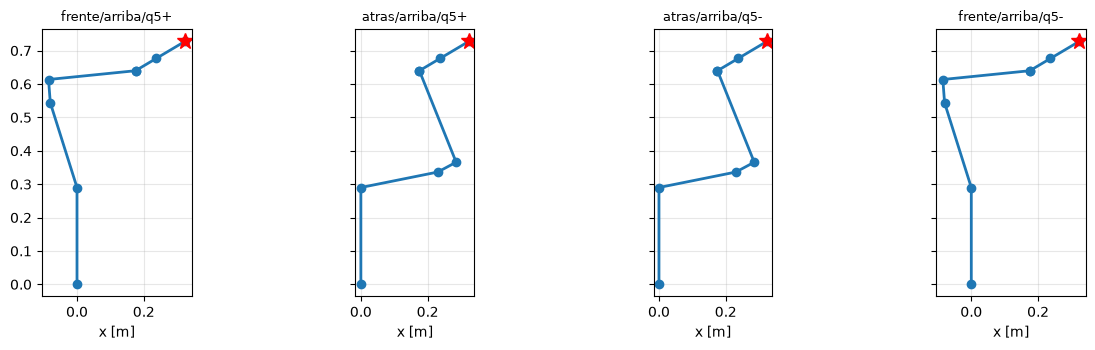

In [3]:
def skeleton(q):
    frames = joint_frames(q)
    pts = [f[:3, 3] for f in frames]
    flange = frames[6]
    tcp = (flange @ np.array([0, 0, 0.100, 1]))[:3]
    return np.array(pts + [tcp])

fig, axes = plt.subplots(1, len(solutions), figsize=(3.2 * len(solutions), 3.6), sharey=True)
for axis, s in zip(np.atleast_1d(axes), solutions):
    pts = skeleton(np.array(s.q))
    axis.plot(pts[:, 0], pts[:, 2], "o-", lw=2)
    axis.plot(*pts[-1][[0, 2]], "r*", ms=12)
    axis.set_title(f"{s.arm}/{s.elbow}/{s.wrist}", fontsize=9); axis.set_aspect("equal"); axis.grid(alpha=.3)
    axis.set_xlabel("x [m]")
plt.tight_layout(); plt.show()

## 3. Pose objetivo con la pinza hacia abajo
Caso típico de pick & place: TCP en $(0.25,-0.15,0.30)$ m con el eje Z de la pinza apuntando a la mesa.

In [4]:
target = pose_matrix((0.25, -0.15, 0.30), rpy_to_matrix(0, np.pi, 0))
sols = inverse_kinematics_tcp(target, np.zeros(6))
best = sols[0]
print("soluciones:", len(sols), "| elegida:", best.arm, best.elbow, best.wrist)
print("q [deg] =", np.rad2deg(best.q).round(2))
print("TCP alcanzado [m] =", forward_kinematics_tcp(np.array(best.q))[:3, 3])
assert position_error_m(target, forward_kinematics_tcp(np.array(best.q))) < 1e-9

soluciones: 1 | elegida: frente arriba q5-
q [deg] = [-30.96  -1.21  30.74  -0.    60.47 -30.96]
TCP alcanzado [m] = [ 0.25 -0.15  0.3 ]


## 4. Poses fuera del alcance
Si la ley de cosenos da un valor fuera de $[-1,1]$ o ninguna solución respeta los límites, la lista queda vacía.

In [5]:
far = np.eye(4); far[:3, 3] = [2.0, 0.0, 0.5]
print("Pose a 2 m de la base ->", inverse_kinematics(far), "(sin solucion)")
near = np.eye(4); near[:3, 3] = [0.05, 0.0, 0.2]
print("Pose pegada a la base  ->", len(inverse_kinematics(near)), "soluciones")

Pose a 2 m de la base -> [] (sin solucion)
Pose pegada a la base  -> 0 soluciones


## 5. Validación estadística
1000 posturas aleatorias dentro de los límites del robot: la IK debe devolver la original y todas las soluciones deben reproducir la pose.

postura original recuperada: 1000/1000
peor error de posicion:    6.59e-16 m   (limite del proyecto: 1e-6 m)
peor error de orientacion: 5.14e-15 rad


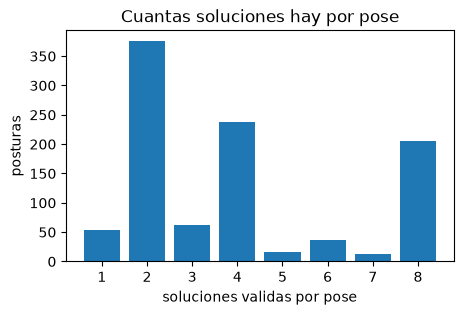

In [6]:
rng = np.random.default_rng(342)
worst_pos = worst_rot = 0.0
counts, recovered = [], 0
for _ in range(1000):
    qr = rng.uniform(LIMITS_RAD[:, 0], LIMITS_RAD[:, 1])
    Tr = forward_kinematics(qr)
    sols = inverse_kinematics(Tr, qr)
    counts.append(len(sols))
    recovered += bool(sols) and np.allclose(sols[0].q, qr, atol=1e-6)
    for s in sols:
        reached = forward_kinematics(np.array(s.q))
        worst_pos = max(worst_pos, position_error_m(Tr, reached))
        worst_rot = max(worst_rot, rotation_error_rad(Tr, reached))
print(f"postura original recuperada: {recovered}/1000")
print(f"peor error de posicion:    {worst_pos:.2e} m   (limite del proyecto: 1e-6 m)")
print(f"peor error de orientacion: {worst_rot:.2e} rad")
assert recovered == 1000 and worst_pos < 1e-6

plt.figure(figsize=(5, 3)); plt.hist(counts, bins=np.arange(0.5, 9.5, 1), rwidth=.8)
plt.xlabel("soluciones validas por pose"); plt.ylabel("posturas"); plt.title("Cuantas soluciones hay por pose"); plt.show()

## Conclusión
- La IK analítica recupera la postura original en las 1000 pruebas, con errores del orden de $10^{-16}$ m, muy por debajo del límite de $10^{-6}$ m.
- Hay hasta 8 soluciones; menos cuando los límites articulares descartan algunas. En el robot se elige la más cercana a la postura actual.
- Los puntos fuera del alcance se detectan sin excepciones: lista vacía.